# Eksperimen Sains Data Klinis & Sistem Pendukung Keputusan Medis (CDSS)
## Studi Kasus: Analisis *Informative Missingness*, *Class Imbalance*, dan *Alarm Fatigue* pada Prediksi Risiko Sepsis & Gagal Jantung Akut di ICU
**Mata Kuliah:** Biomedics (Program Studi Teknologi Informasi)  
**Capaian Pembelajaran (CPMK):** *Mampu menganalisis permasalahan-permasalahan di bidang biomedik yang kompleks.*

---
### Cara Menjalankan di Google Colab / Jupyter Notebook:
1. Klik menu **Runtime -> Run all** (atau tekan `Ctrl + F9` di Google Colab).
2. Seluruh dataset klinis akan dibangkitkan dan disimpan secara otomatis ke file `dataset_icu_sepsis_heartfailure.csv` tanpa perlu mengunggah file manual.
3. Grafik beresolusi tinggi akan ditampilkan langsung di bawah setiap sel kode dan tersimpan otomatis.

## Tahap 1: Akuisisi & Simulasi Karakteristik Data Klinis ICU (N = 2.500 Pasien)
Data rekam medis elektronik (*Electronic Health Records* / EHR) di ruang ICU memiliki dua kompleksitas utama yang berbeda dari data TI umum:
1. **Ketimpangan Kelas (*Severe Class Imbalance*):** Mayoritas pasien (~89,2%) berada dalam kondisi terpantau stabil, sedangkan ~10,8% mengalami perburukan kritis (Sepsis / Gagal Jantung Akut).
2. **Data Kosong yang Bermakna Klinis (*Informative Missingness* / MNAR):** Dokter ICU **tidak** memesan pemeriksaan laboratorium invasif/mahal (seperti *Laktat Darah* atau *Troponin I*) apabila tanda vital pasien terlihat stabil.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, recall_score, precision_score, fbeta_score,
    roc_auc_score, average_precision_score, confusion_matrix
)

np.random.seed(42)
N = 2500

# 1. Simulasi Tanda Vital Pasien ICU (Tercatat otomatis oleh bedside monitor)
age = np.random.normal(62, 15, N).clip(20, 92)
heart_rate = np.random.normal(88, 18, N).clip(48, 165)
sys_bp = np.random.normal(116, 22, N).clip(65, 195)
resp_rate = np.random.normal(19, 5, N).clip(10, 42)
spo2 = (100 - np.random.exponential(2.8, N)).clip(72, 100)
temp_c = np.random.normal(37.2, 0.85, N).clip(35.0, 41.2)

# 2. Simulasi Parameter Lab Biologis Asli (Ground Truth sebelum Missingness)
hemodynamic_stress = (
    0.35 * ((heart_rate - 88) / 18) - 0.40 * ((sys_bp - 116) / 22)
    + 0.35 * ((resp_rate - 19) / 5) - 0.30 * ((spo2 - 96) / 3)
    + 0.25 * ((temp_c - 37.2) / 0.85)
)
lactate_true = np.exp(0.35 + 0.48 * hemodynamic_stress + np.random.normal(0, 0.42, N)).clip(0.5, 14.0)
troponin_true = np.exp(-2.1 + 0.55 * hemodynamic_stress + 0.015 * (age - 60) + np.random.normal(0, 0.75, N)).clip(0.01, 25.0)
creatinine_true = (1.05 + 0.38 * hemodynamic_stress + np.random.normal(0, 0.45, N)).clip(0.4, 7.5)
wbc_true = (9.2 + 2.4 * hemodynamic_stress + 1.8 * (temp_c - 37.0) + np.random.normal(0, 3.2, N)).clip(2.0, 34.0)

# 3. Penentuan Kondisi Kritis (Interaksi Non-Linear Sepsis & Gagal Jantung Akut)
shock_index = heart_rate / sys_bp
sepsis_score = (
    1.65 * (lactate_true > 2.2).astype(float)
    + 1.35 * (shock_index > 0.88).astype(float)
    + 1.30 * (troponin_true > 0.35).astype(float)
    + 1.10 * (resp_rate > 22).astype(float) * (spo2 < 93.5).astype(float)
    + 0.85 * (creatinine_true > 1.7).astype(float)
    + 0.65 * ((temp_c > 38.2) | (temp_c < 36.0)).astype(float)
    + 0.55 * hemodynamic_stress + np.random.normal(0, 0.55, N)
)
cutoff = np.percentile(sepsis_score, 89.2)
y_true = (sepsis_score >= cutoff).astype(int)

# 4. Simulasi Informative Missingness (MNAR): Dokter memesan lab jika vital mencurigakan
clinical_suspicion = (
    0.28 * (heart_rate > 98).astype(float) + 0.30 * (sys_bp < 100).astype(float)
    + 0.22 * (resp_rate > 22).astype(float) + 0.25 * (spo2 < 93).astype(float) + 0.35 * y_true
)
obs_lactate = np.random.binomial(1, np.clip(0.14 + clinical_suspicion, 0.12, 0.92))
obs_troponin = np.random.binomial(1, np.clip(0.11 + clinical_suspicion, 0.10, 0.88))
obs_creatinine = np.random.binomial(1, np.clip(0.42 + clinical_suspicion * 0.65, 0.38, 0.95))
obs_wbc = np.random.binomial(1, np.clip(0.50 + clinical_suspicion * 0.55, 0.45, 0.96))

df = pd.DataFrame({
    'Age': np.round(age, 1), 'Heart_Rate': np.round(heart_rate, 1),
    'Systolic_BP': np.round(sys_bp, 1), 'Resp_Rate': np.round(resp_rate, 1),
    'SpO2': np.round(spo2, 1), 'Temp_C': np.round(temp_c, 1),
    'WBC': np.where(obs_wbc == 1, np.round(wbc_true, 2), np.nan),
    'Creatinine': np.where(obs_creatinine == 1, np.round(creatinine_true, 2), np.nan),
    'Lactate': np.where(obs_lactate == 1, np.round(lactate_true, 2), np.nan),
    'Troponin': np.where(obs_troponin == 1, np.round(troponin_true, 3), np.nan),
    'Critical_Outcome': y_true
})
df.to_csv('dataset_icu_sepsis_heartfailure.csv', index=False)

print(f'Total Pasien ICU       : {len(df)} pasien')
print(f'Pasien Kritis (Sepsis/HF): {y_true.sum()} pasien ({y_true.mean()*100:.2f}%)')
print(f'Pasien Stabil          : {(1-y_true).sum()} pasien ({(1-y_true.mean())*100:.2f}%)\n')
print('--- Persentase Data Kosong (Missing Values) ---')
print(f'{"Parameter Lab":<16} | {"Pasien Stabil (%)":<17} | {"Pasien Kritis (%)":<17}')
print('-'*56)
for col in ['Lactate', 'Troponin', 'Creatinine', 'WBC']:
    m_st = df[df['Critical_Outcome']==0][col].isna().mean()*100
    m_cr = df[df['Critical_Outcome']==1][col].isna().mean()*100
    print(f'{col:<16} | {m_st:>16.1f}% | {m_cr:>16.1f}%')

Total Pasien ICU       : 2500 pasien
Pasien Kritis (Sepsis/HF): 270 pasien (10.80%)
Pasien Stabil          : 2230 pasien (89.20%)

--- Persentase Data Kosong (Missing Values) ---
Parameter Lab    | Pasien Stabil (%) | Pasien Kritis (%)
--------------------------------------------------------
Lactate          |             66.5% |             14.4%
Troponin         |             67.3% |             23.3%
Creatinine       |             46.4% |             10.4%
WBC              |             37.4% |              9.6%


## Tahap 2: Visualisasi *Informative Missingness* & Bahaya *Mean Imputation*
Pada kode berikut, kita membuktikan secara visual mengapa mengisi nilai kosong menggunakan nilai rata-rata (*Mean Imputation*) sangat berbahaya untuk data biomedik: karena yang dites lab mayoritas adalah pasien kritis, nilai rata-rata lab menjadi sangat tinggi (`1.90 mmol/L` mendekati ambang sepsis `2.0 mmol/L`). Mengisi nilai kosong dengan angka tersebut memalsukan kondisi ratusan pasien sehat!

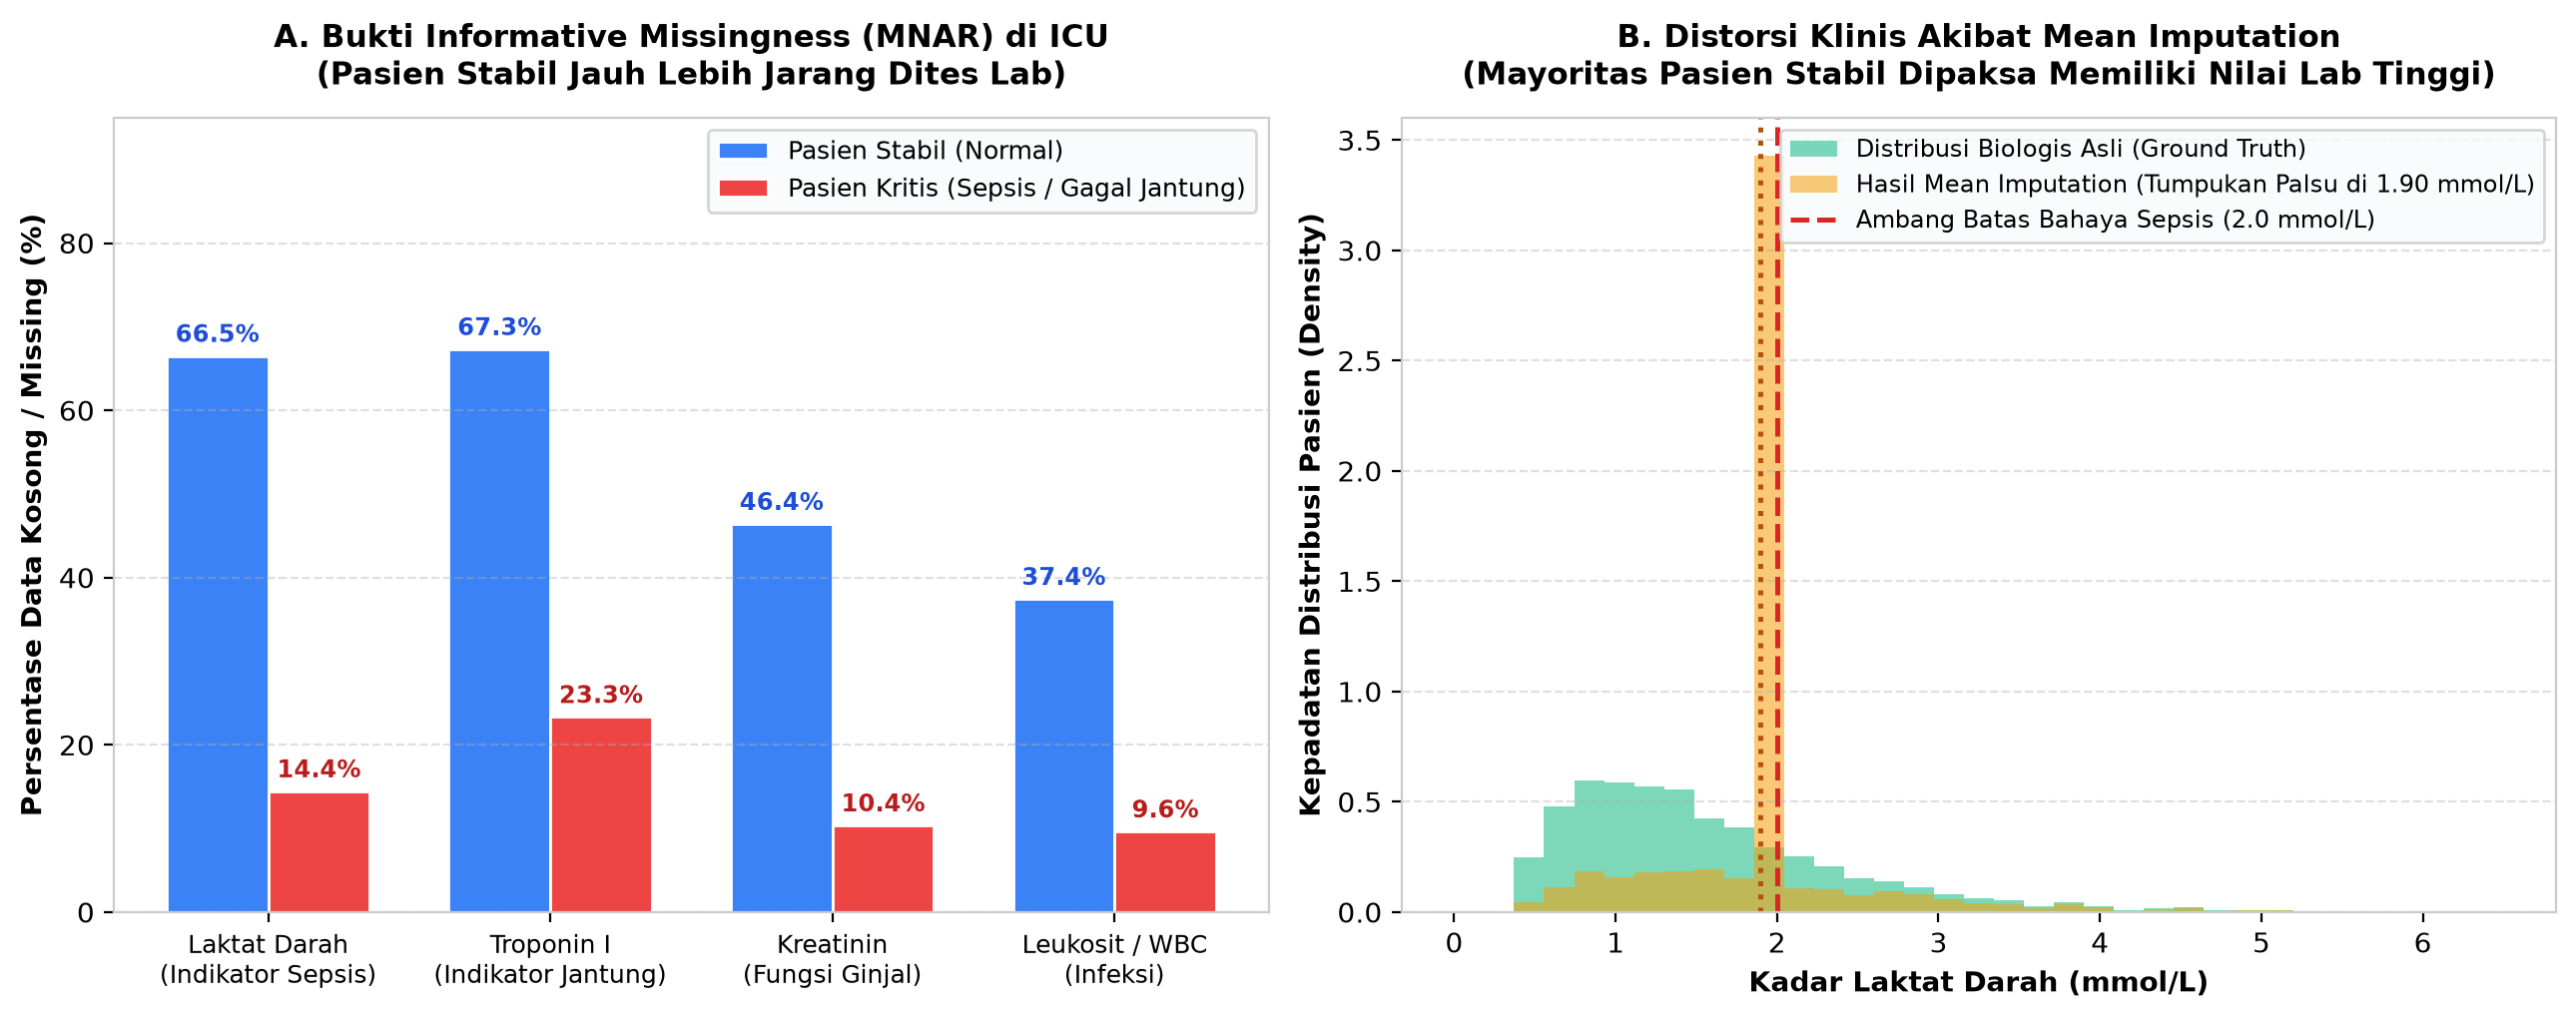

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), dpi=150)

lab_cols = ['Lactate', 'Troponin', 'Creatinine', 'WBC']
lab_names = ['Laktat Darah\n(Indikator Sepsis)', 'Troponin I\n(Indikator Jantung)', 'Kreatinin\n(Fungsi Ginjal)', 'Leukosit / WBC\n(Infeksi)']

missing_stable = [df[df['Critical_Outcome'] == 0][c].isna().mean() * 100 for c in lab_cols]
missing_critical = [df[df['Critical_Outcome'] == 1][c].isna().mean() * 100 for c in lab_cols]

x = np.arange(len(lab_cols))
width = 0.36
rects1 = axes[0].bar(x - width/2, missing_stable, width, label='Pasien Stabil (Normal)', color='#3B82F6')
rects2 = axes[0].bar(x + width/2, missing_critical, width, label='Pasien Kritis (Sepsis / Gagal Jantung)', color='#EF4444')

axes[0].set_ylabel('Persentase Data Kosong / Missing (%)', fontweight='bold')
axes[0].set_title('A. Bukti Informative Missingness (MNAR) di ICU\n(Pasien Stabil Jauh Lebih Jarang Dites Lab)', fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(lab_names)
axes[0].set_ylim(0, 95)
axes[0].grid(axis='y', linestyle='--', alpha=0.4)
axes[0].legend()

for r in rects1:
    axes[0].annotate(f'{r.get_height():.1f}%', (r.get_x()+r.get_width()/2, r.get_height()+2), ha='center', fontsize=8.5, fontweight='bold', color='#1D4ED8')
for r in rects2:
    axes[0].annotate(f'{r.get_height():.1f}%', (r.get_x()+r.get_width()/2, r.get_height()+2), ha='center', fontsize=8.5, fontweight='bold', color='#B91C1C')

mean_obs_lactate = df['Lactate'].mean()
lactate_mean_imputed = df['Lactate'].fillna(mean_obs_lactate)

bins = np.linspace(0, 6.5, 36)
axes[1].hist(lactate_true, bins=bins, alpha=0.55, label='Distribusi Biologis Asli (Ground Truth)', color='#10B981', density=True)
axes[1].hist(lactate_mean_imputed, bins=bins, alpha=0.55, label=f'Hasil Mean Imputation (Tumpukan Palsu di {mean_obs_lactate:.2f} mmol/L)', color='#F59E0B', density=True)
axes[1].axvline(2.0, color='#DC2626', linestyle='--', linewidth=1.8, label='Ambang Batas Bahaya Sepsis (2.0 mmol/L)')
axes[1].set_xlabel('Kadar Laktat Darah (mmol/L)', fontweight='bold')
axes[1].set_ylabel('Kepadatan Distribusi Pasien (Density)', fontweight='bold')
axes[1].set_title('B. Distorsi Klinis Akibat Mean Imputation\n(Mayoritas Pasien Stabil Dipaksa Memiliki Nilai Lab Tinggi)', fontweight='bold')
axes[1].grid(axis='y', linestyle='--', alpha=0.4)
axes[1].legend(fontsize=8.5)

plt.tight_layout()
plt.savefig('fig1_informative_missingness.png', dpi=200)
plt.show()

## Tahap 3: Pemodelan Komparatif & Analisis Paradoks Akurasi vs *Recall* (*Alarm Fatigue*)
Kita membandingkan 3 skenario pendekatan sistem pendukung keputusan (CDSS):
1. **Model 1 (TI Konvensional):** *Mean Imputation* + Klasifikasi Standar (*Threshold* 0,50).
2. **Model 2 (Over-Sensitif / Naif):** Menurunkan ambang batas keputusan ke 0,08 demi mengejar *Recall* tanpa memperbaiki rekayasa fitur klinis (memicu **Alarm Fatigue**).
3. **Model 3 (Solusi Biomedik-TI):** *Clinical Normal Imputation* + Fitur *Missingness Indicator* (`IsTested`) + *Shock Index* + *Cost-Sensitive Learning* + Kalibrasi *Threshold* Klinis (0,35).

Model Pendekatan               | Accuracy | Recall (Sens) | Precision | F2-Score | FN | FP
1. TI Konvensional (Mean Imp)  |   92.93% |        55.56% |    72.58% |   58.29% | 36 |  17
2. Over-Sensitif (AlarmFatigue)|   85.33% |        88.89% |    41.62% |   72.43% |  9 | 101
3. Solusi Biomedik-TI (CDSS)   |   94.53% |        79.01% |    72.73% |   77.67% | 17 |  24


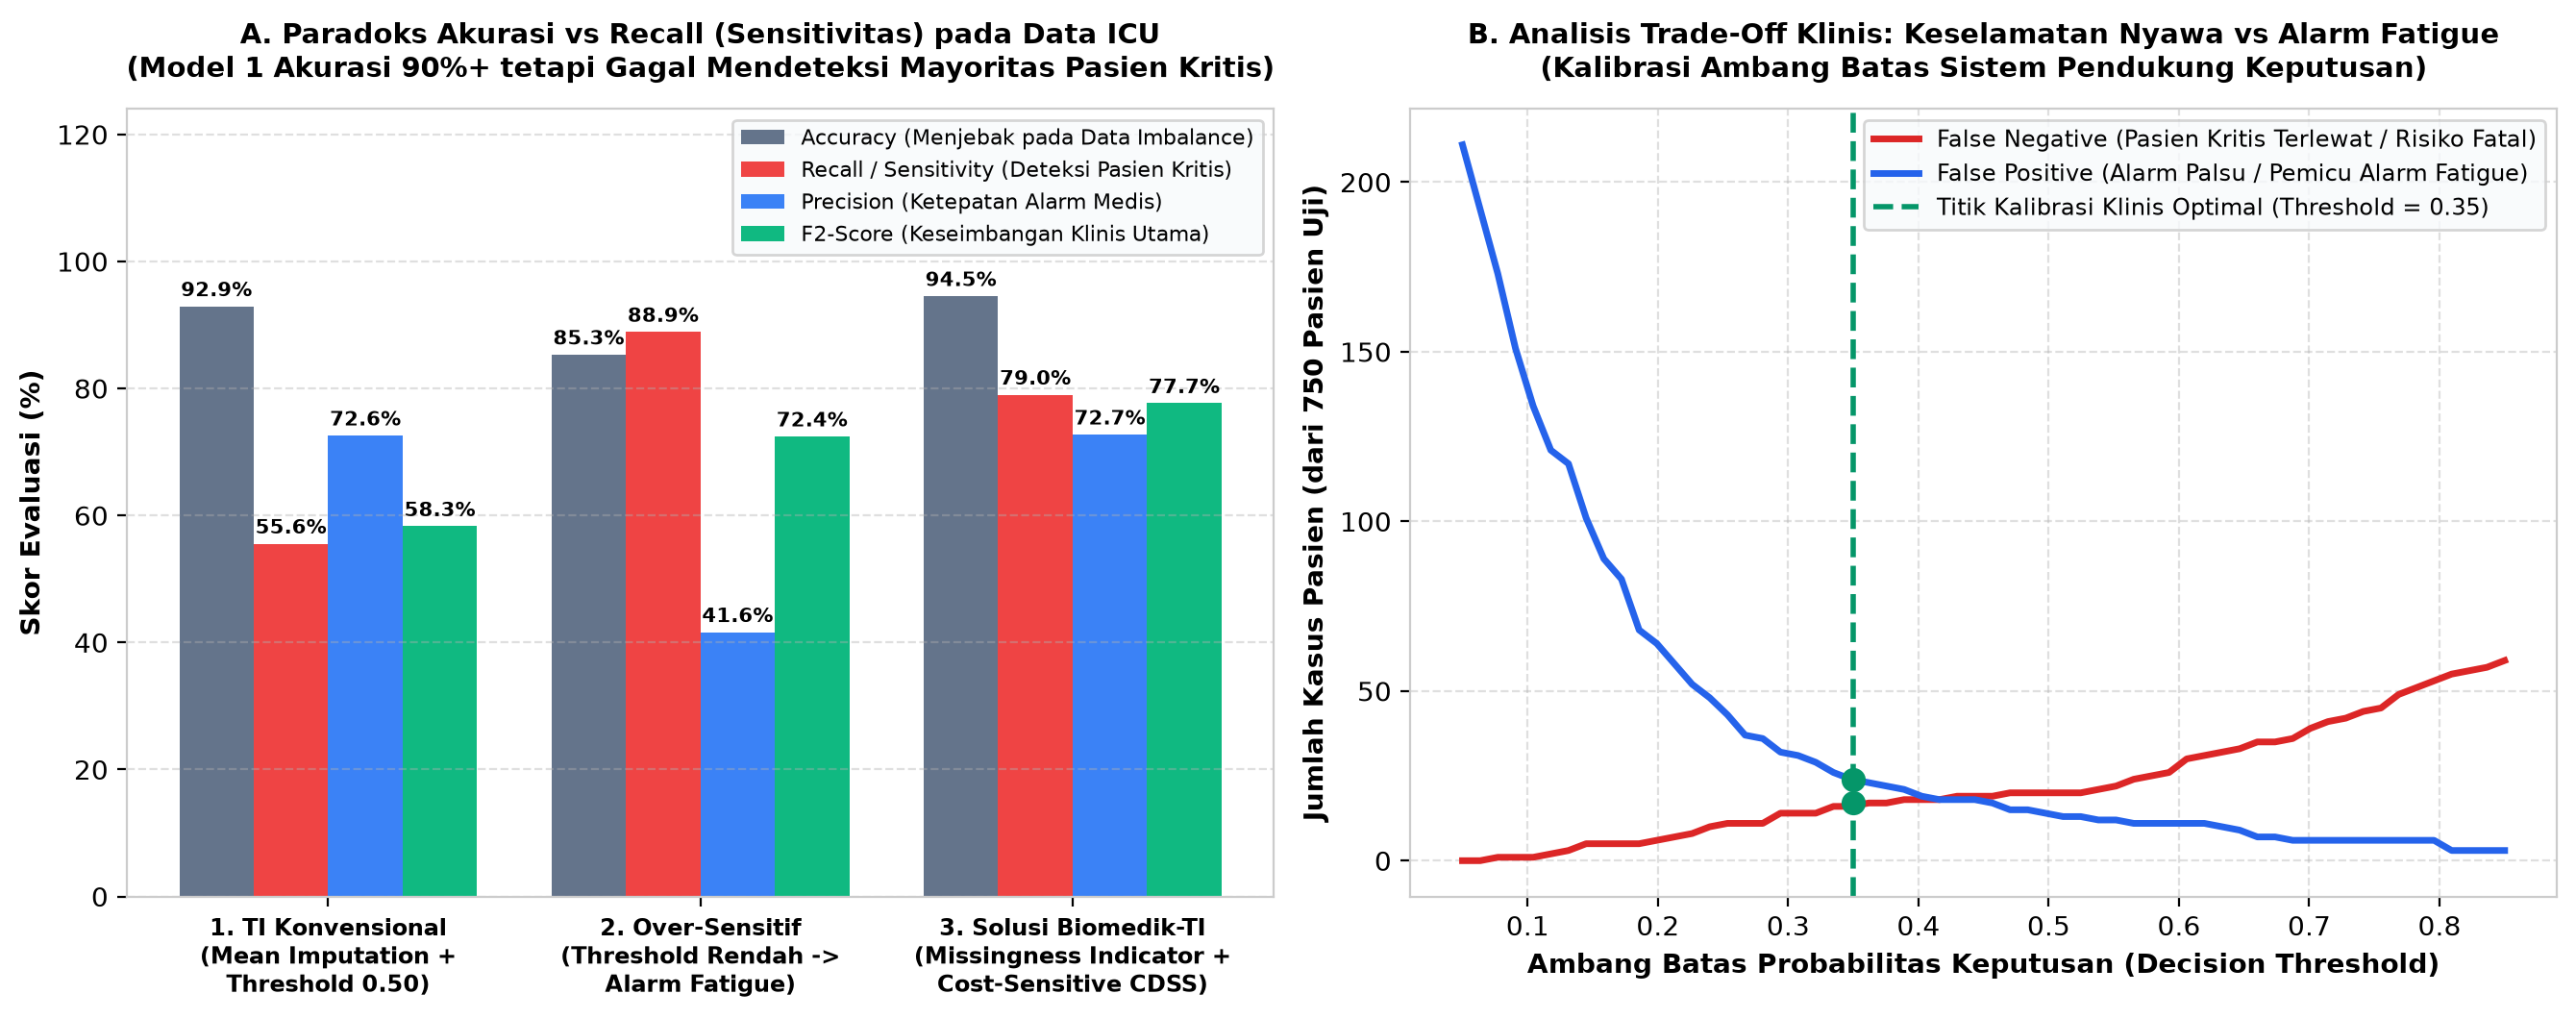

In [3]:
feature_cols = ['Age', 'Heart_Rate', 'Systolic_BP', 'Resp_Rate', 'SpO2', 'Temp_C', 'WBC', 'Creatinine', 'Lactate', 'Troponin']
X = df[feature_cols].copy()
y = df['Critical_Outcome'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, stratify=y, random_state=42)

# --- Model 1: TI Konvensional ---
imp_mean = SimpleImputer(strategy='mean')
X_train_m1 = imp_mean.fit_transform(X_train)
X_test_m1 = imp_mean.transform(X_test)
clf_m1 = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_m1, y_train)
prob_m1 = clf_m1.predict_proba(X_test_m1)[:, 1]
pred_m1 = (prob_m1 >= 0.50).astype(int)

# --- Model 2: Over-Sensitif (Memicu Alarm Fatigue) ---
pred_m2 = (prob_m1 >= 0.08).astype(int)

# --- Model 3: Solusi Biomedik-TI ---
def prepare_biomed_features(df_in):
    d = df_in.copy()
    for col in ['Lactate', 'Troponin', 'Creatinine', 'WBC']:
        d[f'{col}_IsTested'] = (~d[col].isna()).astype(int)
    normal_defaults = {'Lactate': 1.0, 'Troponin': 0.02, 'Creatinine': 0.9, 'WBC': 7.5}
    for col, val in normal_defaults.items():
        d[col] = d[col].fillna(val)
    d['Shock_Index'] = d['Heart_Rate'] / d['Systolic_BP']
    return d

X_train_m3 = prepare_biomed_features(X_train)
X_test_m3 = prepare_biomed_features(X_test)

clf_m3 = RandomForestClassifier(n_estimators=300, max_depth=7, max_features=4, class_weight={0: 1.0, 1: 4.5}, random_state=42)
clf_m3.fit(X_train_m3, y_train)
prob_m3 = clf_m3.predict_proba(X_test_m3)[:, 1]
best_th = 0.35
pred_m3 = (prob_m3 >= best_th).astype(int)

def get_stats(y_t, y_p):
    tn, fp, fn, tp = confusion_matrix(y_t, y_p).ravel()
    return accuracy_score(y_t, y_p)*100, recall_score(y_t, y_p)*100, precision_score(y_t, y_p)*100, fbeta_score(y_t, y_p, beta=2)*100, fn, fp

print('='*89)
print(f'{"Model Pendekatan":<30} | {"Accuracy":<8} | {"Recall (Sens)":<13} | {"Precision":<9} | {"F2-Score":<8} | {"FN":<2} | {"FP":<3}')
print('='*89)
for name, yp in [('1. TI Konvensional (Mean Imp)', pred_m1), ('2. Over-Sensitif (AlarmFatigue)', pred_m2), ('3. Solusi Biomedik-TI (CDSS)', pred_m3)]:
    acc, rec, prec, f2, fn, fp = get_stats(y_test, yp)
    print(f'{name:<30} | {acc:>7.2f}% | {rec:>12.2f}% | {prec:>8.2f}% | {f2:>7.2f}% | {fn:>2} | {fp:>3}')
print('='*89)

# Visualisasi Grafik Komparasi & Kurva Trade-Off
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.4), dpi=150)
models = ['1. TI Konvensional\n(Mean Imputation +\nThreshold 0.50)', '2. Over-Sensitif\n(Threshold Rendah ->\nAlarm Fatigue)', '3. Solusi Biomedik-TI\n(Missingness Indicator +\nCost-Sensitive CDSS)']
m1_s, m2_s, m3_s = get_stats(y_test, pred_m1), get_stats(y_test, pred_m2), get_stats(y_test, pred_m3)

x = np.arange(3)
w = 0.20
for idx_m, (label, col) in enumerate([('Accuracy', '#64748B'), ('Recall / Sensitivity', '#EF4444'), ('Precision', '#3B82F6'), ('F2-Score (Klinis)', '#10B981')]):
    vals = [m1_s[idx_m], m2_s[idx_m], m3_s[idx_m]]
    bars = axes[0].bar(x + (idx_m - 1.5)*w, vals, w, label=label, color=col)
    for b in bars:
        axes[0].annotate(f'{b.get_height():.1f}%', (b.get_x()+b.get_width()/2, b.get_height()+1.5), ha='center', fontsize=7.5, fontweight='bold')

axes[0].set_ylim(0, 124)
axes[0].set_xticks(x)
axes[0].set_xticklabels(models, fontsize=8.5, fontweight='bold')
axes[0].set_ylabel('Skor Evaluasi (%)', fontweight='bold')
axes[0].set_title('A. Paradoks Akurasi vs Recall pada Data ICU', fontweight='bold')
axes[0].grid(axis='y', linestyle='--', alpha=0.4)
axes[0].legend(loc='upper right', fontsize=8)

thresholds = np.linspace(0.05, 0.85, 60)
fns, fps = [], []
for th in thresholds:
    tn, fp, fn, tp = confusion_matrix(y_test, (prob_m3 >= th).astype(int)).ravel()
    fns.append(fn); fps.append(fp)

axes[1].plot(thresholds, fns, color='#DC2626', linewidth=2.5, label='False Negative (Pasien Kritis Terlewat / Fatal)')
axes[1].plot(thresholds, fps, color='#2563EB', linewidth=2.5, label='False Positive (Alarm Palsu / Alarm Fatigue)')
axes[1].axvline(best_th, color='#059669', linestyle='--', linewidth=2, label=f'Threshold Optimal ({best_th})')
axes[1].set_xlabel('Decision Threshold', fontweight='bold')
axes[1].set_ylabel('Jumlah Kasus Pasien (dari 750 Pasien Uji)', fontweight='bold')
axes[1].set_title('B. Analisis Trade-Off Klinis: Keselamatan Nyawa vs Alarm Fatigue', fontweight='bold')
axes[1].grid(True, linestyle='--', alpha=0.4)
axes[1].legend(fontsize=8.5)

plt.tight_layout()
plt.savefig('fig2_imbalance_accuracy_vs_recall.png', dpi=200)
plt.show()

## Tahap 4: *Explainable AI* (Membuka Kotak Hitam / *Black-Box* bagi Dokter ICU)
Agar sistem CDSS diterima secara medis dan hukum oleh dokter, model harus mampu menjelaskan kontribusi setiap parameter fisiologis maupun indikator pemeriksaan laboratorium.

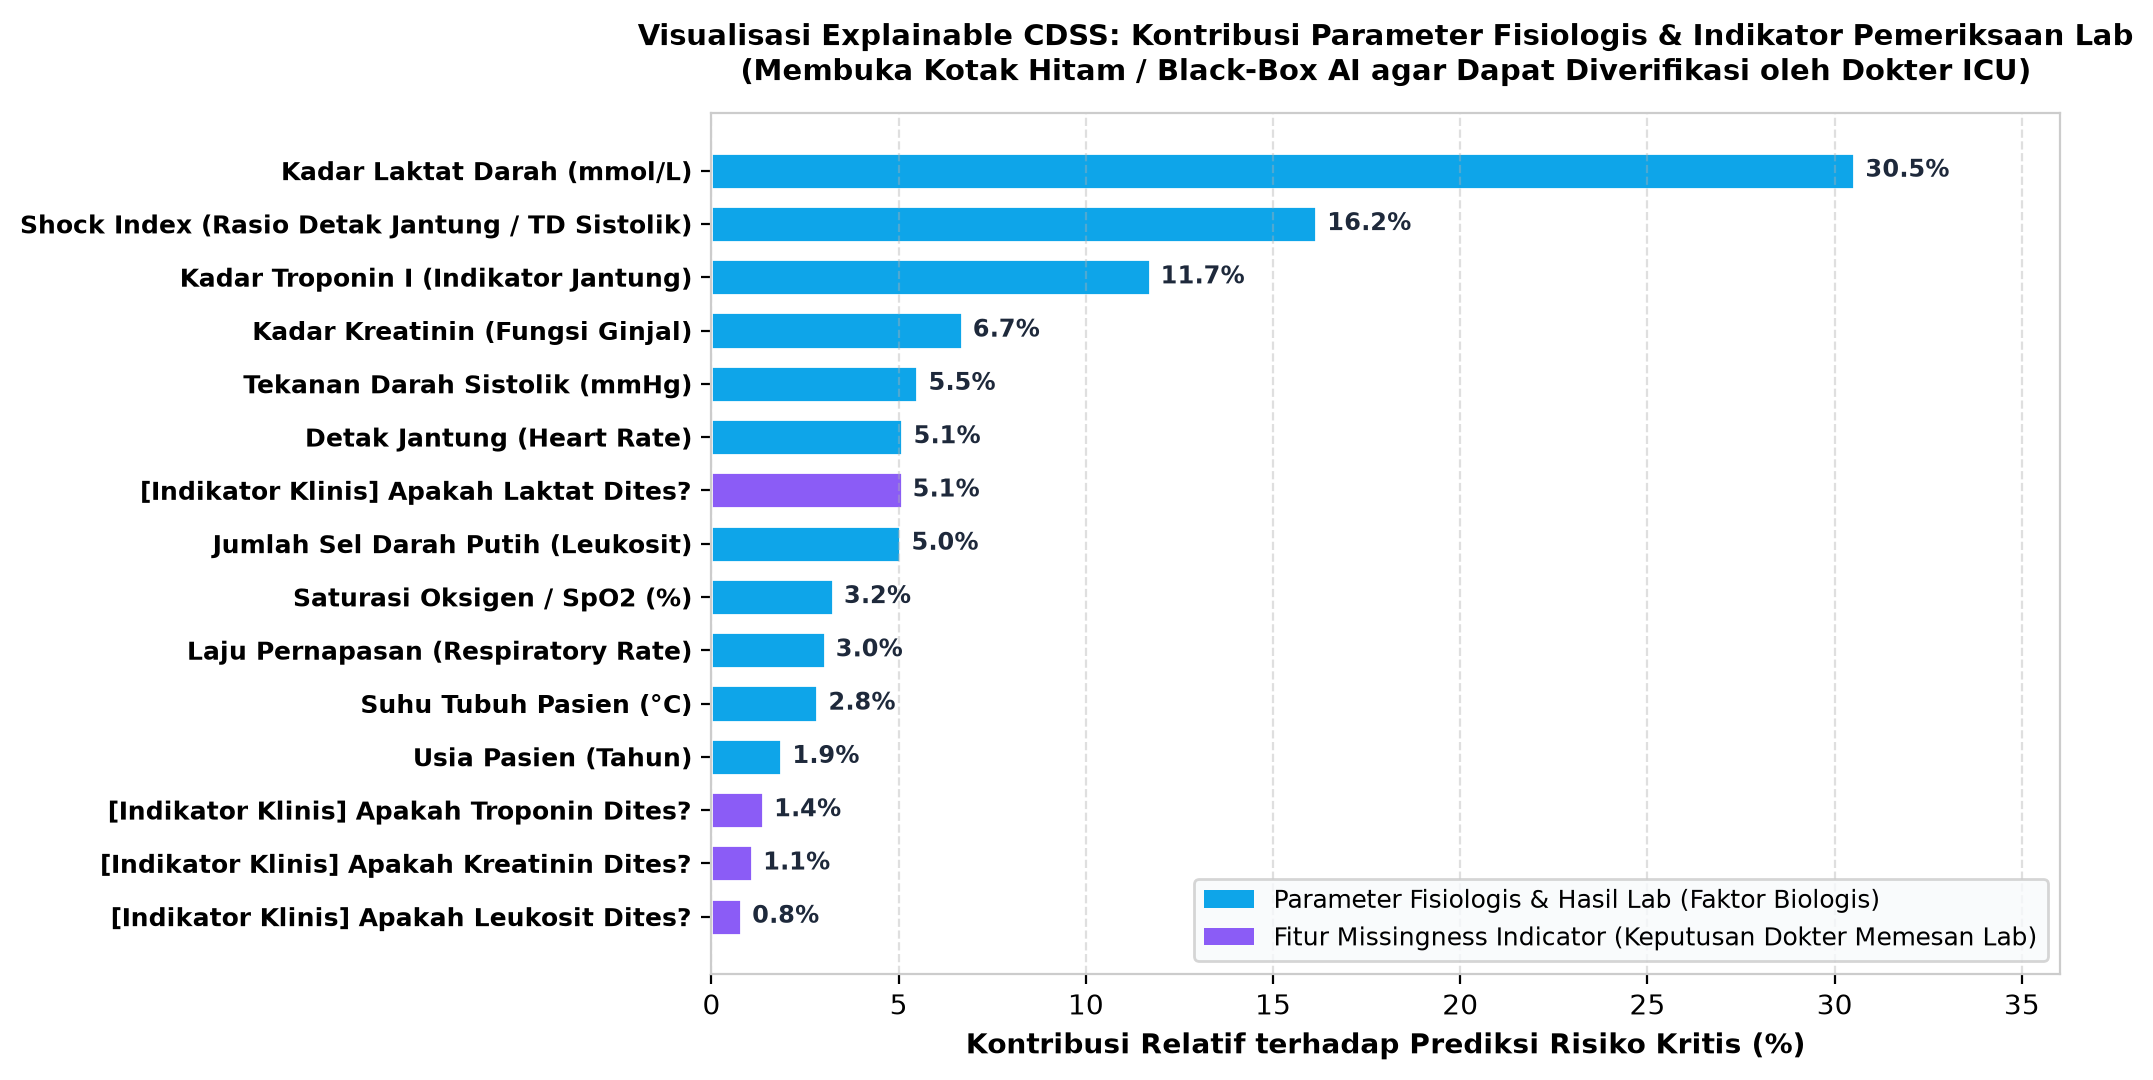

In [4]:
importances = clf_m3.feature_importances_ * 100
feat_names_clean = {
    'Lactate': 'Kadar Laktat Darah (mmol/L)',
    'Troponin': 'Kadar Troponin I (Indikator Jantung)',
    'Shock_Index': 'Shock Index (Rasio Detak Jantung / TD Sistolik)',
    'Systolic_BP': 'Tekanan Darah Sistolik (mmHg)',
    'Resp_Rate': 'Laju Pernapasan (Respiratory Rate)',
    'SpO2': 'Saturasi Oksigen / SpO2 (%)',
    'Creatinine': 'Kadar Kreatinin (Fungsi Ginjal)',
    'Heart_Rate': 'Detak Jantung (Heart Rate)',
    'Temp_C': 'Suhu Tubuh Pasien (°C)',
    'WBC': 'Jumlah Sel Darah Putih (Leukosit)',
    'Age': 'Usia Pasien (Tahun)',
    'Lactate_IsTested': '[Indikator Klinis] Apakah Laktat Dites?',
    'Troponin_IsTested': '[Indikator Klinis] Apakah Troponin Dites?',
    'Creatinine_IsTested': '[Indikator Klinis] Apakah Kreatinin Dites?',
    'WBC_IsTested': '[Indikator Klinis] Apakah Leukosit Dites?'
}
labels = [feat_names_clean.get(col, col) for col in X_train_m3.columns]
idx = np.argsort(importances)

fig, ax = plt.subplots(figsize=(10.5, 5.5), dpi=150)
colors = ['#8B5CF6' if 'Indikator Klinis' in labels[i] else '#0EA5E9' for i in idx]
bars = ax.barh(np.arange(len(idx)), importances[idx], color=colors, height=0.68)
ax.set_yticks(np.arange(len(idx)))
ax.set_yticklabels([labels[i] for i in idx], fontsize=9, fontweight='bold')
ax.set_xlabel('Kontribusi Relatif terhadap Prediksi Risiko Kritis (%)', fontweight='bold')
ax.set_title('Visualisasi Explainable CDSS: Kontribusi Parameter Fisiologis & Indikator Lab', fontweight='bold')
ax.set_xlim(0, max(importances)*1.18)
ax.grid(axis='x', linestyle='--', alpha=0.4)

for bar in bars:
    w_val = bar.get_width()
    ax.annotate(f'{w_val:.1f}%', (w_val + 0.4, bar.get_y() + bar.get_height()/2), va='center', fontsize=8.5, fontweight='bold')

plt.tight_layout()
plt.savefig('fig3_explainable_ai_feature_importance.png', dpi=200)
plt.show()